# Q2 — Tempo de execução dos métodos

## Dados

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from covariancia import mcovar1, mcovar2, mcovar3, mcovar4

df = pd.read_csv("wall+following+robot+navigation+data/sensor_readings_24.data", header=None)
X = df.iloc[:, :24].to_numpy().T  # p x N
X.shape

(24, 5456)

## Métodos

In [2]:
metodos = {
    "Método 1": mcovar1,
    "Método 2": mcovar2,
    "Método 3": mcovar3,
    "Método 4": mcovar4,
    "np.cov": lambda X: np.cov(X, bias=True),
}

## Medição (100 rodadas)

In [3]:
R = 100
nomes = list(metodos)
rng = np.random.default_rng(42)

for f in metodos.values():  # aquecimento
    f(X)

tempos = pd.DataFrame(np.zeros((R, len(nomes))), columns=nomes)
for r in range(R):
    for nome in rng.permutation(nomes):  # ordem embaralhada a cada rodada
        t0 = time.perf_counter()
        metodos[nome](X)
        tempos.loc[r, nome] = (time.perf_counter() - t0) * 1e3  # ms

## Média e desvio-padrão

In [4]:
tempos.agg(["mean", "std", "median"]).T.sort_values("mean").rename(
    columns={"mean": "média (ms)", "std": "desvio-padrão (ms)", "median": "mediana (ms)"})

,média (ms),desvio-padrão (ms),mediana (ms)
Método 4,0.416644,0.131386,0.36745
Método 2,0.907529,0.288664,0.83965
np.cov,1.047345,0.314632,0.95355
Método 1,36.386351,6.303565,35.16790
Método 3,46.608681,5.979919,45.21585


## Histogramas

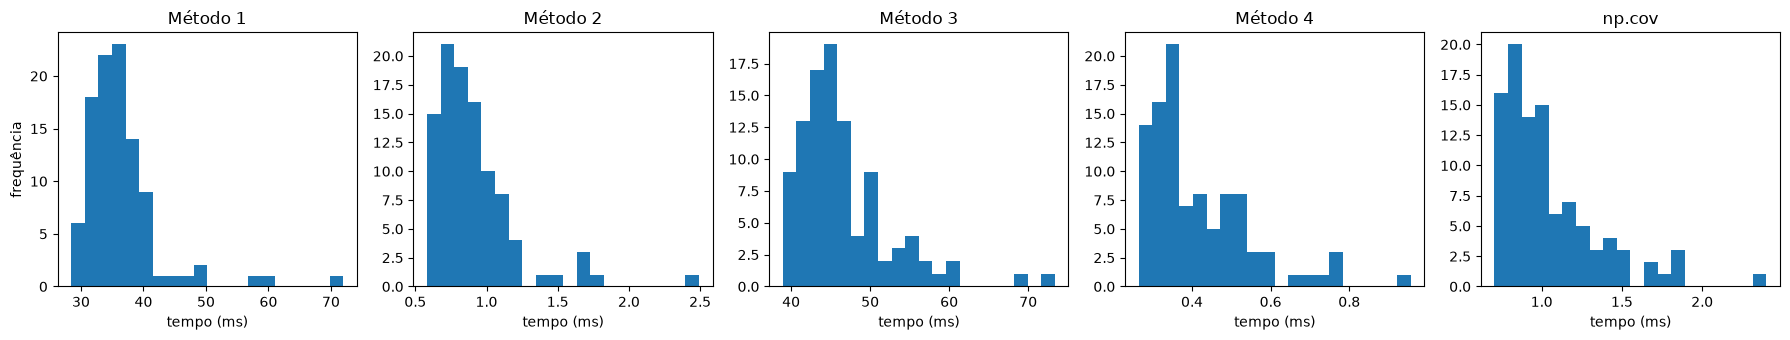

In [5]:
fig, axes = plt.subplots(1, len(nomes), figsize=(18, 3.5))
for ax, nome in zip(axes, nomes):
    ax.hist(tempos[nome], bins=20)
    ax.set_title(nome)
    ax.set_xlabel("tempo (ms)")
axes[0].set_ylabel("frequência")
plt.tight_layout()
plt.show()

## Violin plot

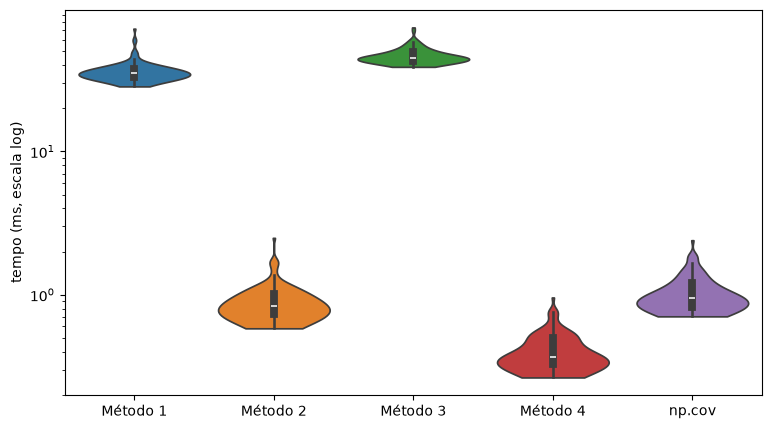

In [6]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=tempos, cut=0)
plt.yscale("log")
plt.ylabel("tempo (ms, escala log)")
plt.show()